
<h1 id="MK-Praktikum-Unggulan-Universitas-Gunadarma">MK Praktikum Unggulan Universitas Gunadarma<a class="anchor-link" href="#MK-Praktikum-Unggulan-Universitas-Gunadarma">¶</a></h1><h1 id="Nama-Mata-Kuliah:-Praktikum-Komputasi-Big-Data-(Tingkat-2)">Nama Mata Kuliah: Praktikum Komputasi Big Data (Tingkat 2)<a class="anchor-link" href="#Nama-Mata-Kuliah:-Praktikum-Komputasi-Big-Data-(Tingkat-2)">¶</a></h1><hr/>



<h1 id="Pertemuan-VII">Pertemuan VII<a class="anchor-link" href="#Pertemuan-VII">¶</a></h1><p>Pada pertemuan ini Anda akan melanjutkan tahapan pengolahan data yaitu data training dan model generation.</p>



<h1 id="Import-Dataset">Import Dataset<a class="anchor-link" href="#Import-Dataset">¶</a></h1>


In [1]:
# Import library
import pandas as pd
import numpy as np

# Import dataset
data = pd.read_csv('https://gitlab.com/andreass.bayu/file-directory/-/raw/main/adult.csv')

# Lihat 5 data teratas
data.head(5)


,age,workclass,fnlwgt,education,educational-num,marital-status,occupation,relationship,race,gender,capital-gain,capital-loss,hours-per-week,native-country,income
0,25,Private,226802,11th,7,Never-married,Machine-op-inspct,Own-child,Black,Male,0,0,40,United-States,<=50K
1,38,Private,89814,HS-grad,9,Married-civ-spouse,Farming-fishing,Husband,White,Male,0,0,50,United-States,<=50K
2,28,Local-gov,336951,Assoc-acdm,12,Married-civ-spouse,Protective-serv,Husband,White,Male,0,0,40,United-States,>50K
3,44,Private,160323,Some-college,10,Married-civ-spouse,Machine-op-inspct,Husband,Black,Male,7688,0,40,United-States,>50K
4,18,?,103497,Some-college,10,Never-married,?,Own-child,White,Female,0,0,30,United-States,<=50K



<h1 id="Review-Dataset">Review Dataset<a class="anchor-link" href="#Review-Dataset">¶</a></h1>


In [2]:
# Lihat statistik deskripsi data dari tiap kolom dengan menggunakan fungsi describe
data.describe()


,age,fnlwgt,educational-num,capital-gain,capital-loss,hours-per-week
count,48842.000000,4.884200e+04,48842.000000,48842.000000,48842.000000,48842.000000
mean,38.643585,1.896641e+05,10.078089,1079.067626,87.502314,40.422382
std,13.710510,1.056040e+05,2.570973,7452.019058,403.004552,12.391444
min,17.000000,1.228500e+04,1.000000,0.000000,0.000000,1.000000
25%,28.000000,1.175505e+05,9.000000,0.000000,0.000000,40.000000
50%,37.000000,1.781445e+05,10.000000,0.000000,0.000000,40.000000
75%,48.000000,2.376420e+05,12.000000,0.000000,0.000000,45.000000
max,90.000000,1.490400e+06,16.000000,99999.000000,4356.000000,99.000000


In [3]:
# Lihat tipe data dari tiap kolom dengan menggunakan fungsi dtypes
data.dtypes


age                 int64
workclass          object
fnlwgt              int64
education          object
educational-num     int64
marital-status     object
occupation         object
relationship       object
race               object
gender             object
capital-gain        int64
capital-loss        int64
hours-per-week      int64
native-country     object
income             object
dtype: object

In [4]:
# Melihat jumlah atribut dan dimensi data (baris dan kolom) dengan menggunakan fungsi shape
data.shape


(48842, 15)

In [5]:
# Menghitung dan melihat jumlah data per label kelas
for col in data.columns:
  if data[col].dtype == "object":
    print('Attribute name:',col)
    print('-------------------')
    print(data[col].value_counts())
    print('-------------------')


Attribute name: workclass
-------------------
workclass
Private             33906
Self-emp-not-inc     3862
Local-gov            3136
?                    2799
State-gov            1981
Self-emp-inc         1695
Federal-gov          1432
Without-pay            21
Never-worked           10
Name: count, dtype: int64
-------------------
Attribute name: education
-------------------
education
HS-grad         15784
Some-college    10878
Bachelors        8025
Masters          2657
Assoc-voc        2061
11th             1812
Assoc-acdm       1601
10th             1389
7th-8th           955
Prof-school       834
9th               756
12th              657
Doctorate         594
5th-6th           509
1st-4th           247
Preschool          83
Name: count, dtype: int64
-------------------
Attribute name: marital-status
-------------------
marital-status
Married-civ-spouse       22379
Never-married            16117
Divorced                  6633
Separated                 1530
Widowed             

<Axes: xlabel='income', ylabel='count'>

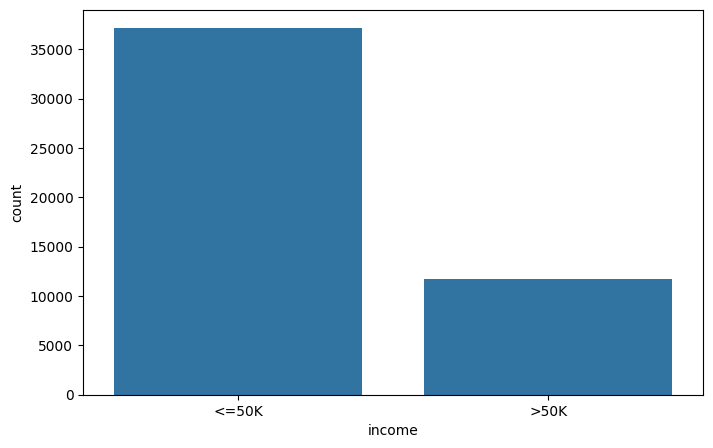

In [6]:
# Import library seaborn untuk visualisasi
import seaborn as sns
import matplotlib.pyplot as plt
%matplotlib inline

# Plot figure untuk menentukan distribusi kelas
plt.figure(figsize=(8,5))

# Menghitung baris setiap kelas
sns.countplot(x="income", data=data)



<p><strong>Diketahui bahwa dataset memiliki distribusi kelas yang tidak seimbang (imbalanced) sehingga secara teknis akan digunakan teknik untuk menangani data yang tidak seimbang.</strong></p>



<h1 id="Dataset-preparation">Dataset preparation<a class="anchor-link" href="#Dataset-preparation">¶</a></h1>


In [7]:
# Buat salinan dataframe
df = data.copy(deep = True)

# Mengubah nilai "?" nilai ke bentuk Na / NaN untuk diproses lebih lanjut
for col in data.columns:
  df[[col]] = data[[col]].replace('?',np.nan)


In [8]:
# Melakukan seleksi kolom fitur/feature columns dari dataset
null_data = df.iloc[:,:-1]

# Temukan nilai null untuk semua atribut dan jumlahkan total nilai null
null_data.isnull().sum()


age                   0
workclass          2799
fnlwgt                0
education             0
educational-num       0
marital-status        0
occupation         2809
relationship          0
race                  0
gender                0
capital-gain          0
capital-loss          0
hours-per-week        0
native-country      857
dtype: int64

In [9]:
# Hapus (drop) semua baris yang memiliki nilai null
df = df.dropna()

# Pilih kolom fitur (feature columns) dari dataset
null_data = df.iloc[:,:-1]

# Cek ulang nilai null
null_data.isnull().sum()


age                0
workclass          0
fnlwgt             0
education          0
educational-num    0
marital-status     0
occupation         0
relationship       0
race               0
gender             0
capital-gain       0
capital-loss       0
hours-per-week     0
native-country     0
dtype: int64


<p><strong>StandardScaler</strong> <em>adalah class dari sklearn untuk melakukan normalisasi data agar data yang digunakan tidak memiliki penyimpangan yang besar.</em></p>


In [10]:
# Import library standard scaler
from sklearn.preprocessing import StandardScaler

# Buat dataframe dengan tipe data int64
colname= []
for col in df.columns:
  if df[col].dtype == "int64":
      colname.append(col)

# Buat salinan dataset untuk keperluan persiapan data (data preparation)
df_copy = df.copy(deep = True)
df_fe = df.copy()

# Buat dataframe untuk fitur kategoris (categorical features)
df_fe.drop('income',axis='columns', inplace=True)
df_fe.drop(colname,axis='columns', inplace=True)

# Buat dataframe untuk kelas target (target class)
df_cl = df.copy()
df_cl.drop(df_copy.iloc[:,:-1],axis='columns', inplace=True)

# Membuat objek scaler (scaler object)
std_scaler = StandardScaler()
std_scaler

# Normalisasikan atribut numerik dan tetapkan ke dalam dataframe baru
df_norm = pd.DataFrame(std_scaler.fit_transform(df_copy[colname]), columns=colname)


In [11]:
# Import library Ordinal Encoder dari package library sklearn.preprocessing
from sklearn.preprocessing import OrdinalEncoder
ord_enc = OrdinalEncoder()

# Encode fitur kategoris/categorical features menjadi fitur numerik (numerical features)
for col in df_fe.columns[:]:
  if df_fe[col].dtype == "object":
    df_fe[col] = ord_enc.fit_transform(df_fe[[col]])

# Encode label kategorikal (categorical label) menjadi label biner (binary label)
df_cl["income"] = np.where(df_cl["income"].str.contains(">50K"), 0, 1)


In [12]:
# Masukkan kolom id ke dataset yang berbeda
df_norm.insert(0, 'id', range(0, 0 + len(df_norm)))
df_fe.insert(0, 'id', range(0, 0 + len(df_fe)))
df_cl.insert(0, 'id', range(0, 0 + len(df_cl)))

# Lihat shapes dataset yang telah di proses
print(df_norm.shape)
print(df_fe.shape)
print(df_cl.shape)


(45222, 7)
(45222, 9)
(45222, 2)


In [13]:
# Gabungkan semua dataset
df_feature = pd.merge(df_norm,df_fe, on=["id"])
df_final = pd.merge(df_feature,df_cl, on=["id"])

# Drop kolom id dari gabungan dataset
df_final.drop('id',axis='columns', inplace=True)

# Lihat 5 data teratas dari gabungan dataset
df_final.head(5)


,age,fnlwgt,educational-num,capital-gain,capital-loss,hours-per-week,workclass,education,marital-status,occupation,relationship,race,gender,native-country,income
0,-1.024983,0.350889,-1.221559,-0.146733,-0.21878,-0.078120,2.0,1.0,4.0,6.0,3.0,2.0,1.0,38.0,1
1,-0.041455,-0.945878,-0.438122,-0.146733,-0.21878,0.754701,2.0,11.0,2.0,4.0,0.0,4.0,1.0,38.0,1
2,-0.798015,1.393592,0.737034,-0.146733,-0.21878,-0.078120,1.0,7.0,2.0,10.0,0.0,4.0,1.0,38.0,0
3,0.412481,-0.278420,-0.046403,0.877467,-0.21878,-0.078120,2.0,15.0,2.0,6.0,0.0,2.0,1.0,38.0,0
4,-0.344079,0.084802,-1.613277,-0.146733,-0.21878,-0.910942,2.0,0.0,4.0,7.0,1.0,4.0,1.0,38.0,1



<h1 id="Visualization">Visualization<a class="anchor-link" href="#Visualization">¶</a></h1>


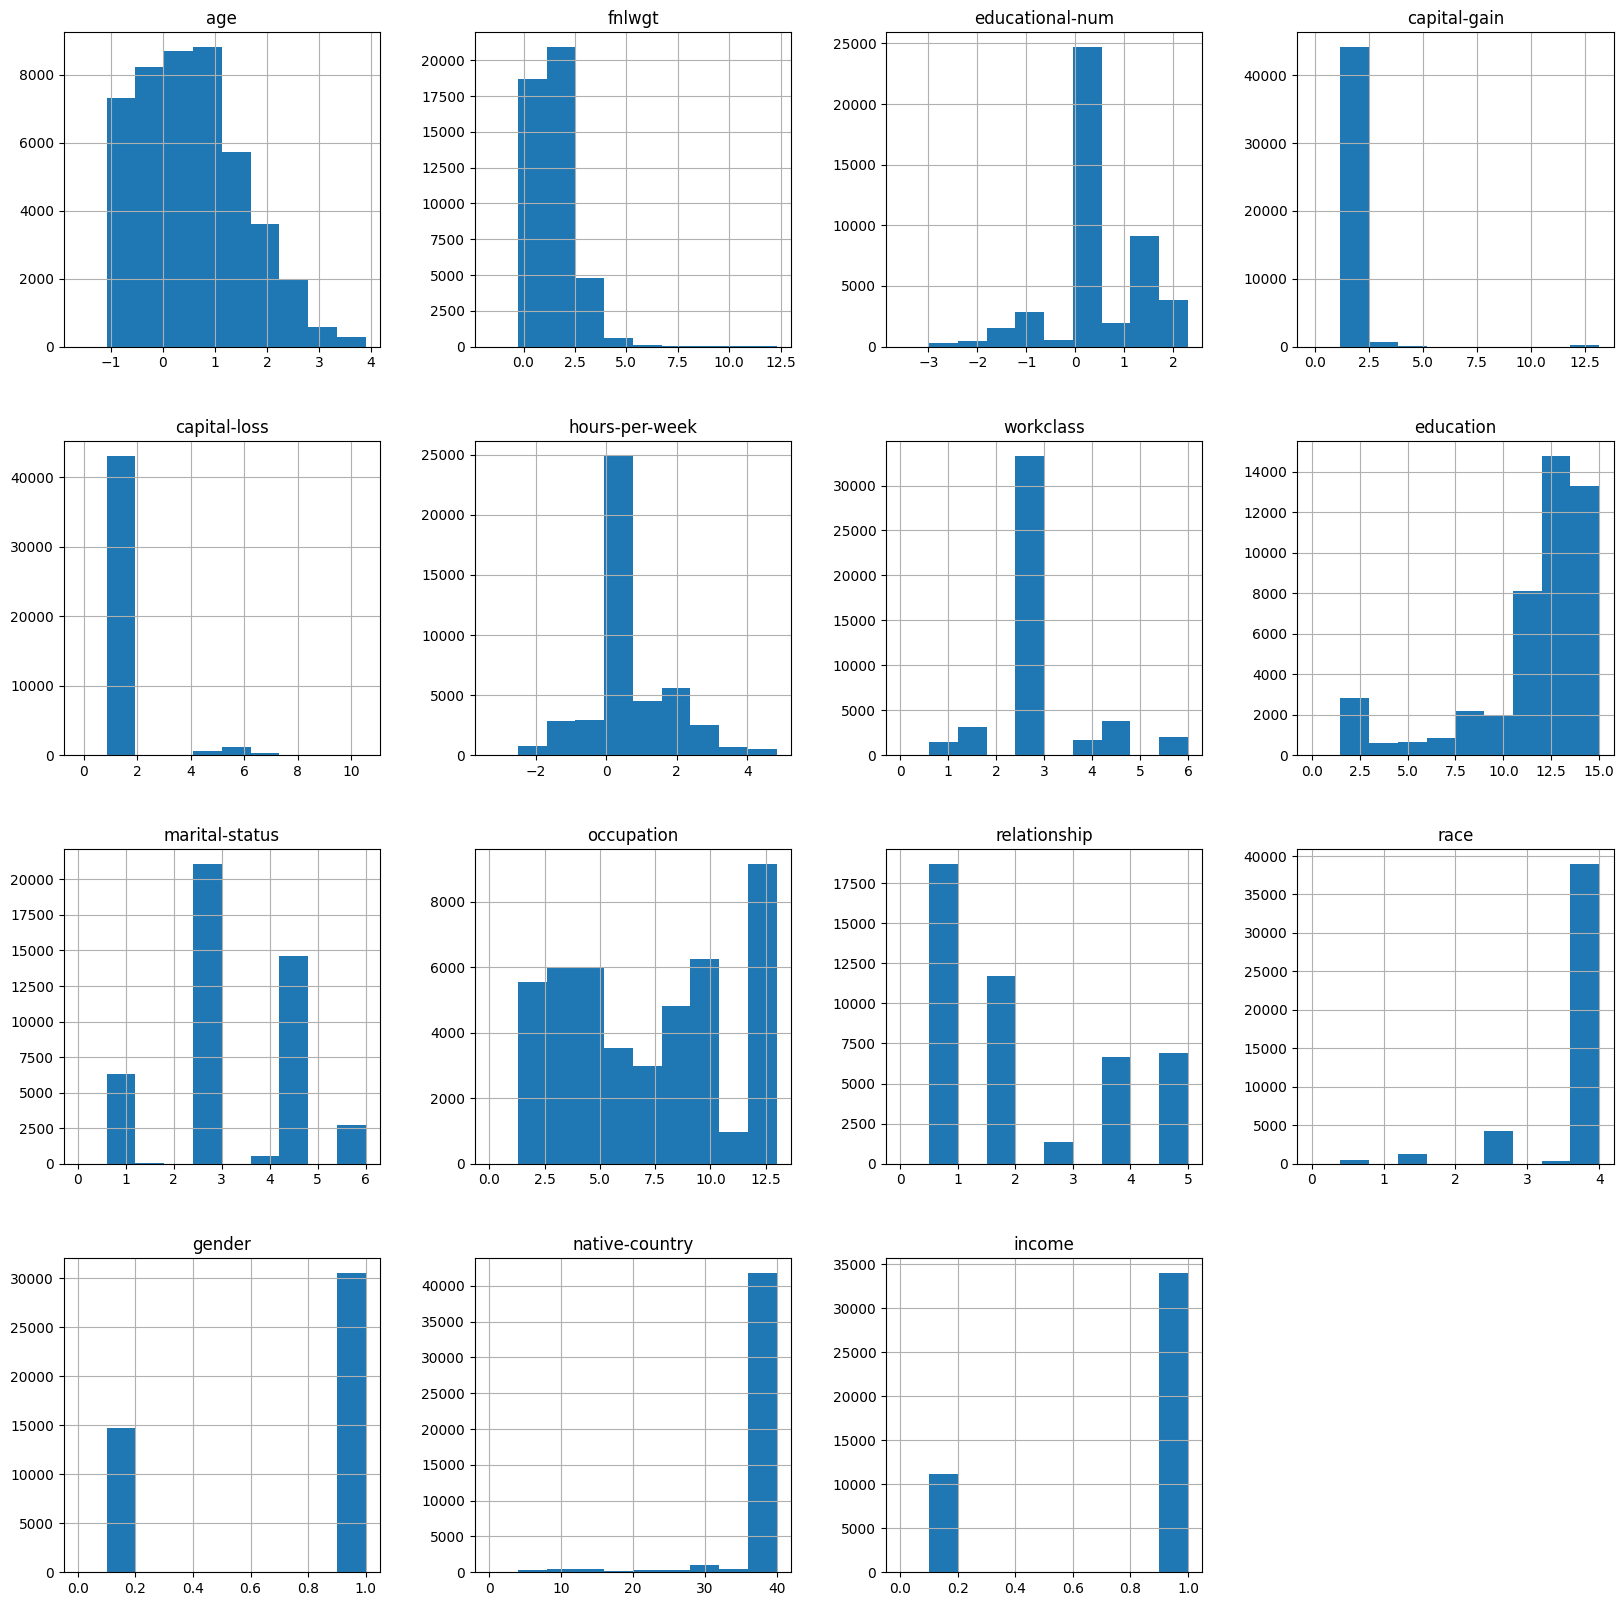

In [14]:
p = df_final.hist(figsize = (20,20))



<p><strong>Scatter matrix plot</strong> adalah plot yang digunakan untuk membuat sekumpulan scatter plot dari beberapa pasang variabel. Hal ini sangat bermanfaat terutama ketika ingin menganalisis bagaimana bentuk hubungan antar variabel. Plot ini sangat bermanfaat untuk digunakan untuk data yang ukurannya tidak terlalu besar. Untuk menggunakan scatter matrix kita harus memanggil fungsi <em>scatter_matrix</em> dari <em>pandas.plotting</em></p>


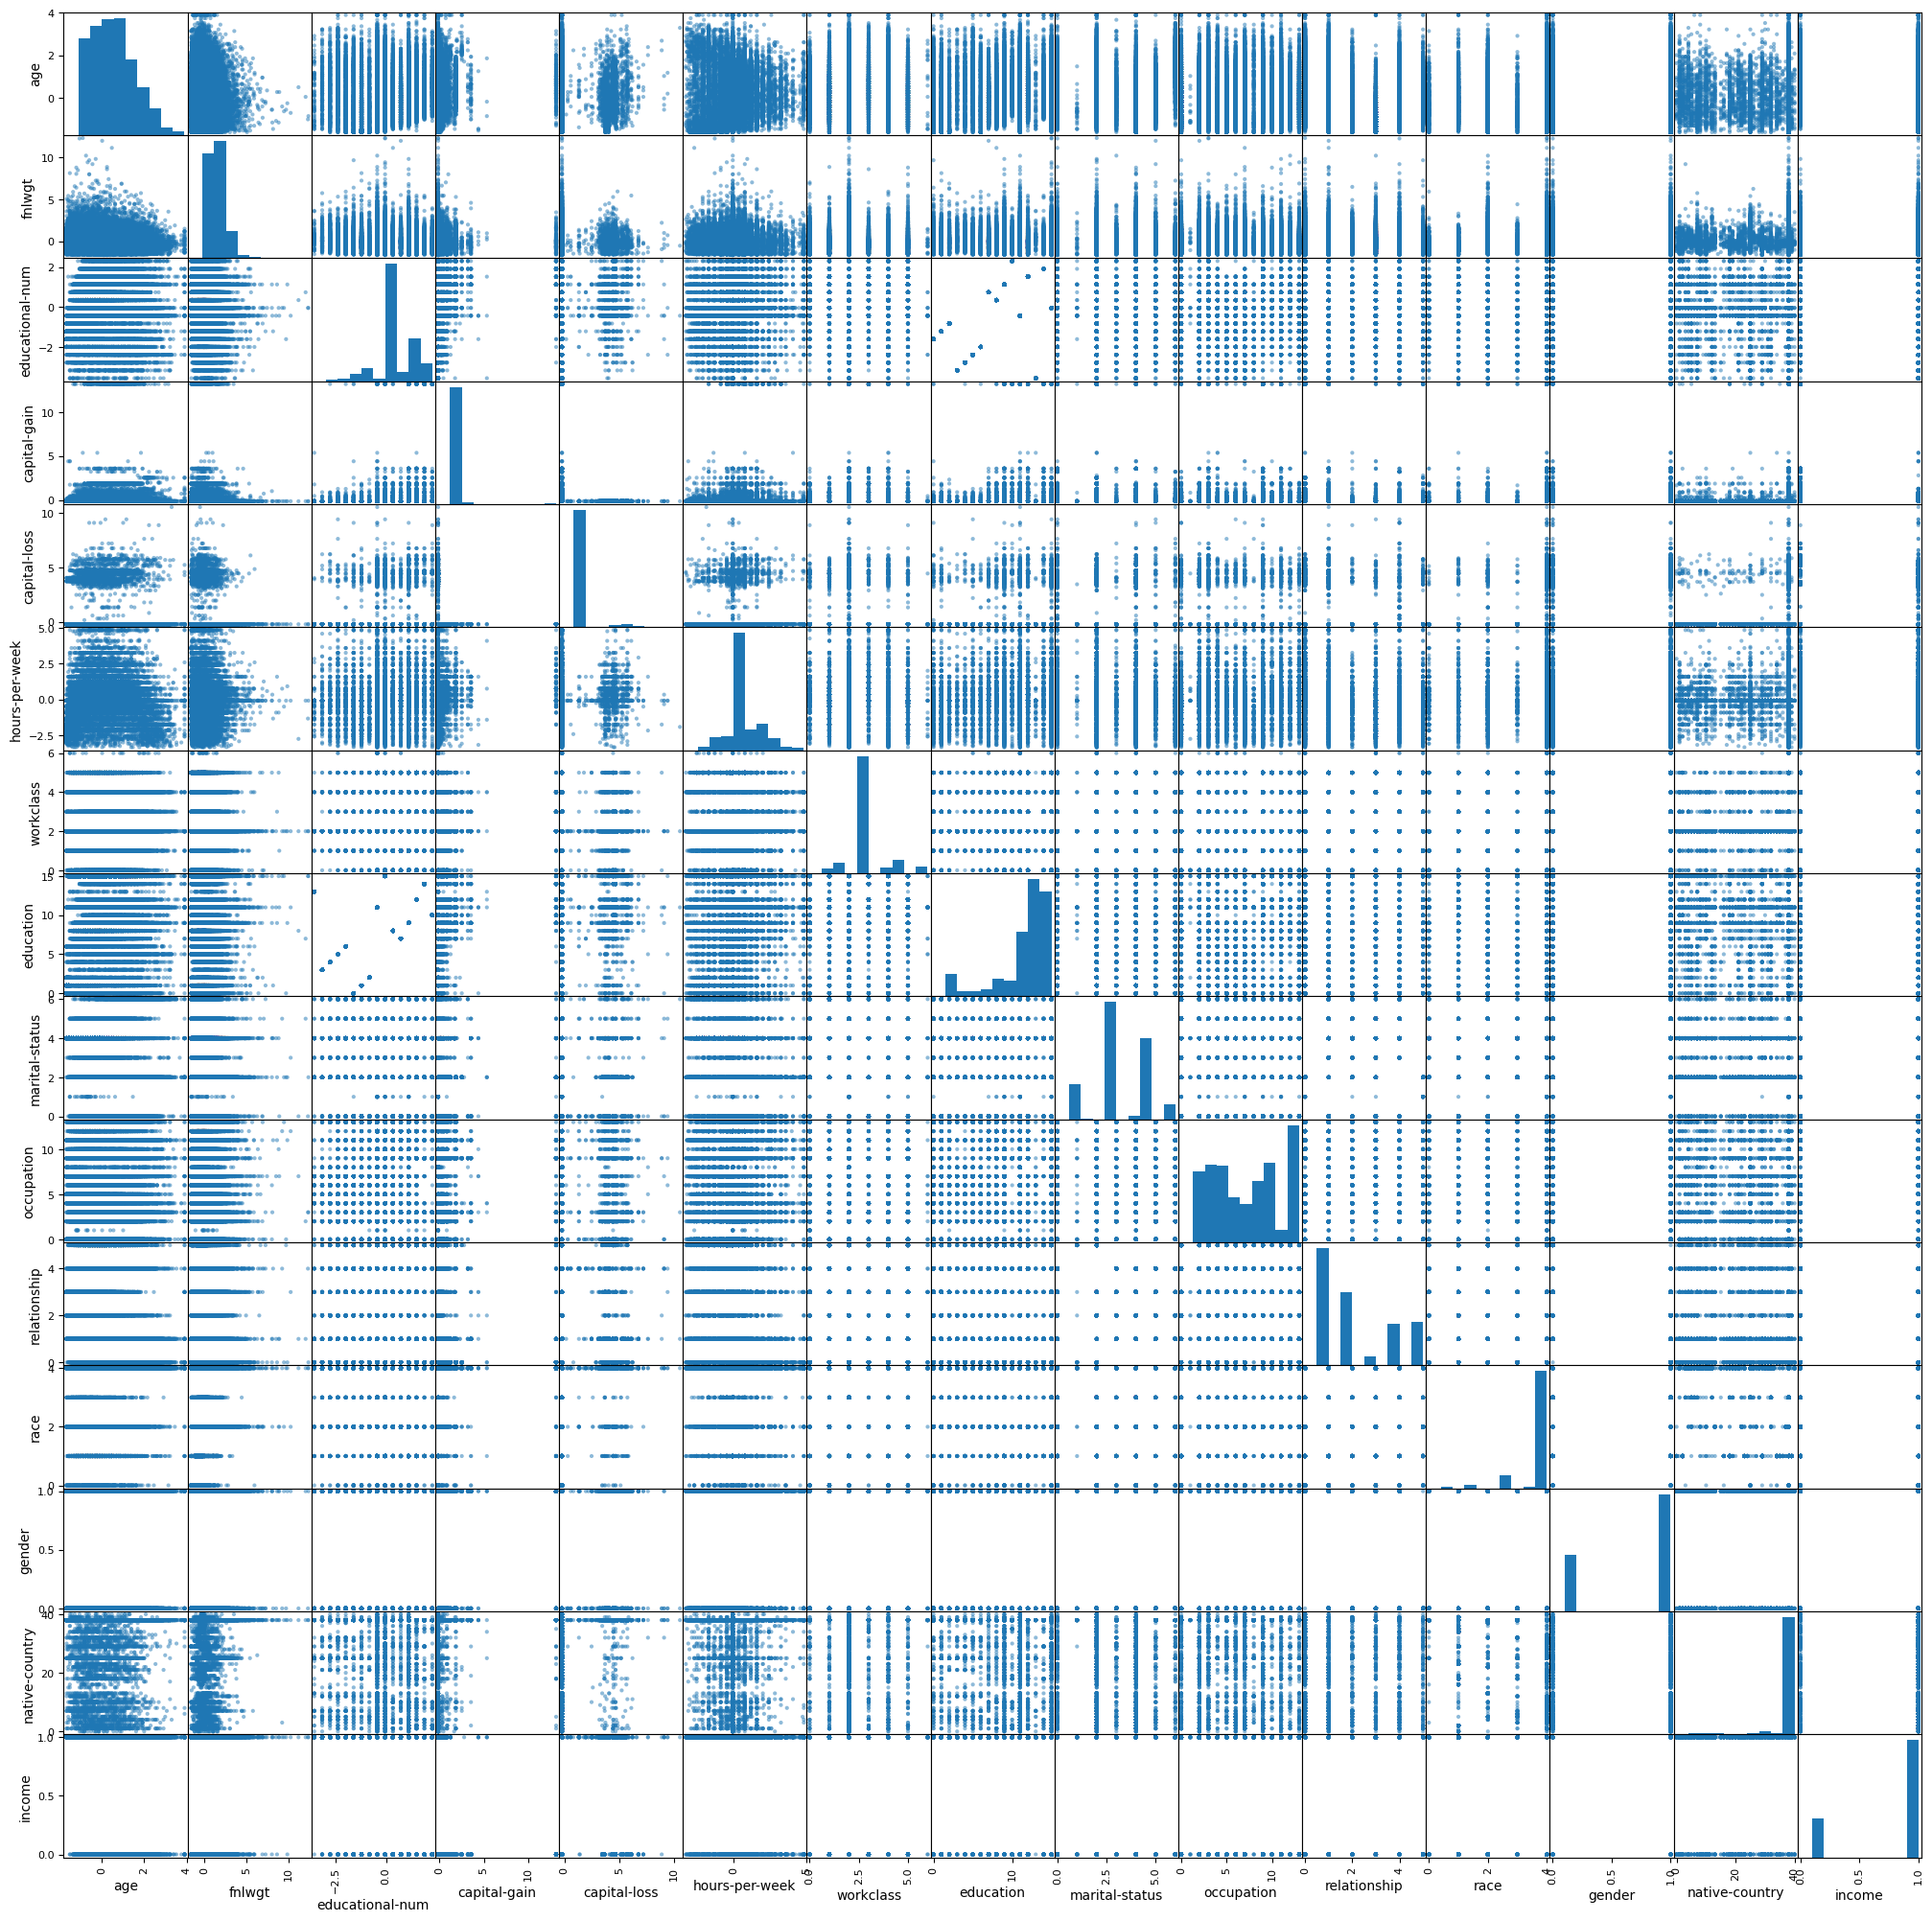

In [15]:
from pandas.plotting import scatter_matrix

p=scatter_matrix(df_final,figsize=(25, 25))


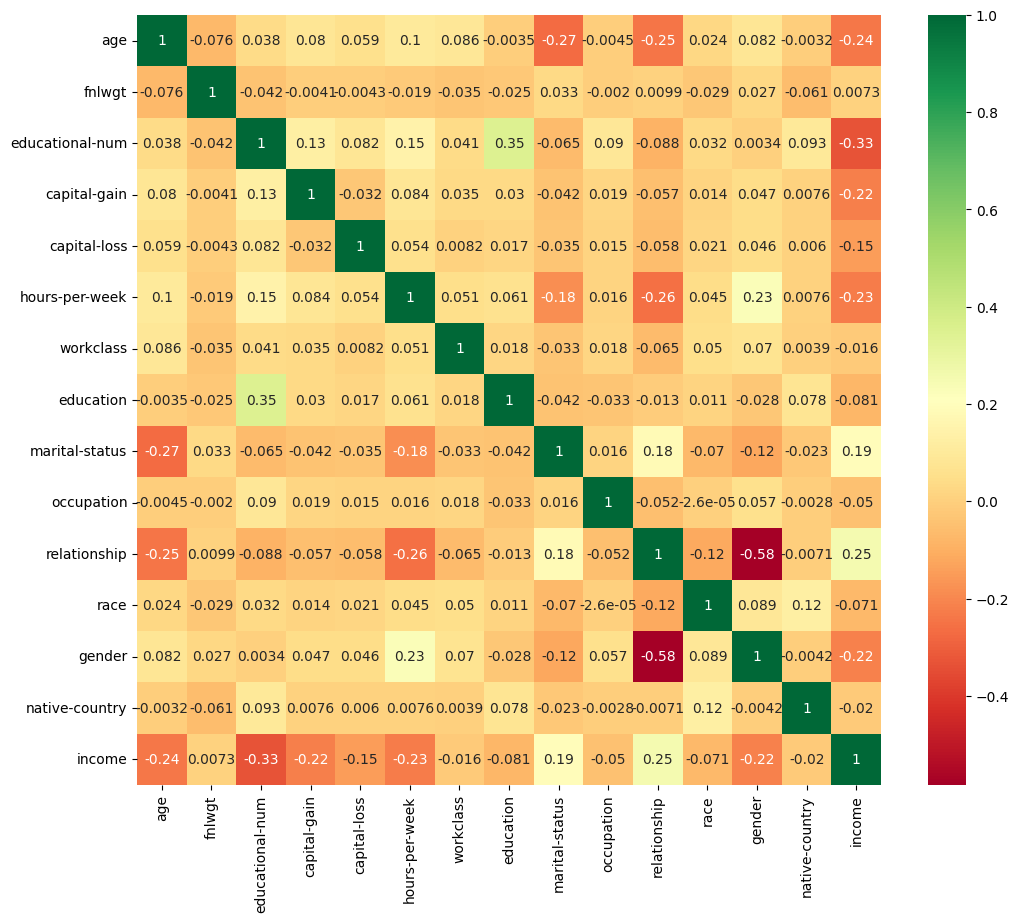

In [16]:
# Buat visualisasi korelasi data dengan heatmap
import seaborn as sns
import matplotlib.pyplot as plt

# Plot heatmap
plt.figure(figsize=(12,10))
p=sns.heatmap(df_final.corr(), annot=True,cmap ='RdYlGn')



<h1 id="Proses-Modelling-dengan-KNN">Proses Modelling dengan KNN<a class="anchor-link" href="#Proses-Modelling-dengan-KNN">¶</a></h1>


In [17]:
import numpy as np
from sklearn.model_selection import KFold

X=df_final.iloc[:,:].to_numpy()
y=df_final.iloc[:,-1:].to_numpy()
kf = KFold(n_splits=5)
kf.get_n_splits(X)

print(kf)

for train_index, test_index in kf.split(X):
    print("TRAIN:", train_index, "TEST:", test_index)
    x_train, x_test = X[train_index], X[test_index]
    y_train, y_test = y[train_index], y[test_index]


KFold(n_splits=5, random_state=None, shuffle=False)
TRAIN: [ 9045  9046  9047 ... 45219 45220 45221] TEST: [   0    1    2 ... 9042 9043 9044]
TRAIN: [    0     1     2 ... 45219 45220 45221] TEST: [ 9045  9046  9047 ... 18087 18088 18089]
TRAIN: [    0     1     2 ... 45219 45220 45221] TEST: [18090 18091 18092 ... 27131 27132 27133]
TRAIN: [    0     1     2 ... 45219 45220 45221] TEST: [27134 27135 27136 ... 36175 36176 36177]
TRAIN: [    0     1     2 ... 36175 36176 36177] TEST: [36178 36179 36180 ... 45219 45220 45221]


In [18]:
print('-------- x axis test ----------')
print(x_test)
print('-------- x axis train ---------')
print(x_train)
print('-------- y axis test ----------')
print(y_test)
print('-------- y axis train ---------')
print(y_train)

print('*******************************')


-------- x axis test ----------
[[ 0.63944887  1.45787715 -0.43812161 ...  1.         38.
   1.        ]
 [ 1.24469679 -1.49349376 -0.046403   ...  1.         38.
   1.        ]
 [-0.26842301 -0.14603391 -0.046403   ...  1.         38.
   1.        ]
 ...
 [ 1.47166476 -0.35805983 -0.43812161 ...  0.         38.
   1.        ]
 [-1.25195088  0.11127873 -0.43812161 ...  1.         38.
   1.        ]
 [ 1.01772882  0.92951628 -0.43812161 ...  0.         38.
   0.        ]]
-------- x axis train ---------
[[-1.02498291  0.35088942 -1.22155881 ...  1.         38.
   1.        ]
 [-0.04145504 -0.94587846 -0.43812161 ...  1.         38.
   1.        ]
 [-0.79801494  1.39359159  0.73703421 ...  1.         38.
   0.        ]
 ...
 [-0.344079   -0.77568407 -0.43812161 ...  1.         10.
   0.        ]
 [ 0.86641684  0.04524191  1.52047141 ...  1.         37.
   1.        ]
 [-0.64670296  0.84029651 -0.43812161 ...  0.         38.
   1.        ]]
-------- y axis test ----------
[[1]
 [1]
 [1]
 

Nilai k KNN yang optimal adalah 3
Skor optimalnya adalah 0.95


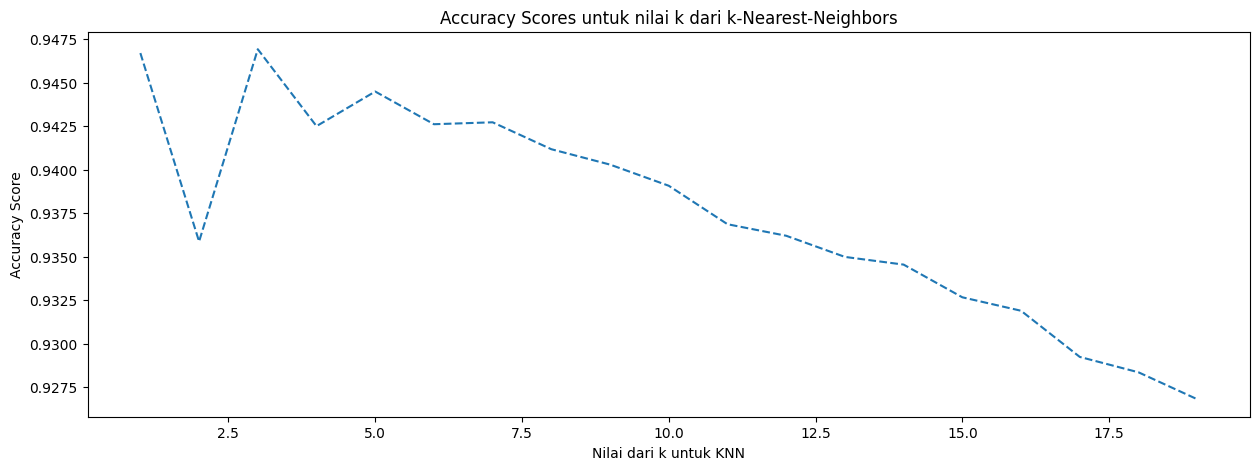

In [19]:
# Import library model KNN dengan alias 'KNeighborsClassifier'
from sklearn.neighbors import KNeighborsClassifier
import sklearn.metrics as metrics
import matplotlib.pyplot as plt

# Buat variabel kosong untuk menyimpan metrik KNN/KNN metrics
scores=[]

# Kita coba nilai k yang berbeda untuk KNN (dari k=1 sampai k=20)
lrange=list(range(1,20))

# Proses perulangan untuk KNN
for k in lrange:
  knn=KNeighborsClassifier(n_neighbors=k) # Masukkan nilai k dan ukuran 'jarak'
  knn.fit(x_train,y_train.ravel()) # Masukan data train/data latih untuk melatih KNN
  y_pred=knn.predict(x_test) # Lihat prediksi KNN dengan memasukkan data uji
  scores.append(metrics.accuracy_score(y_test,y_pred)) # Tambahkan performance metric akurasi
plt.figure(2,figsize=(15,5))

optimal_k = lrange[scores.index(max(scores))]
print("Nilai k KNN yang optimal adalah %d" % optimal_k)
print("Skor optimalnya adalah %.2f" % max(scores))

# Visualisasikan hasilnya
plt.plot(lrange, scores,ls='dashed')
plt.xlabel('Nilai dari k untuk KNN')
plt.ylabel('Accuracy Score')
plt.title('Accuracy Scores untuk nilai k dari k-Nearest-Neighbors')
plt.show()



<h2 id="Tugas-Analisis">Tugas Analisis<a class="anchor-link" href="#Tugas-Analisis">¶</a></h2><p>Berdasarkan hasil percobaan KNN di atas, buatlah hasil analisis dengan menjawab pertanyaan berikut:</p>
<ol>
<li>Pada hasil diagram heatmap, terlihat banyak konfigurasi warna dan nilai yang ditampilkan. Jelaskan arti kolom berwarna merah pada hasil diagram heatmap yang dihasilkan! Pasangan variabel apa saja yang berwarna merah?</li>
<li>Apa yang terjadi jika nilai test size diganti menjadi 0.3 kemudian 0.2 dan 0.1?</li>
<li>Buatlah tabel yang berisi hasil pengujian Anda dan sertakan beberapa nilai k dan nilai akurasi untuk masing-masing skenario uji!</li>
<li>Apakah terjadi perbedaan nilai akurasi model? Jika ya, jelaskan pendapat Anda mengapa hal tersebut bisa terjadi.</li>
<li>Berapa nilai presisi dan recall dari masing-masing model yang Anda coba, serta jelaskan arti dari nilai tersebut.</li>
</ol>


In [20]:
# No 1
print("""
1. Pada diagram heatmap, warna merah menunjukkan nilai korelasi positif yang tinggi
   (mendekati +1) antara dua variabel, sedangkan warna hijau menunjukkan korelasi
   negatif. Semakin merah warnanya, semakin kuat hubungan positif antar variabel;
   jika salah satu variabel naik, variabel lainnya juga cenderung naik.
   Diagonal heatmap selalu merah karena korelasi variabel dengan dirinya sendiri = 1.

   Pasangan variabel yang berwarna merah (korelasi positif) antara lain:
   - educational-num vs education (+0.35)  -> paling merah di luar diagonal
   - marital-status vs relationship (+0.18)
   - race vs native-country (+0.12)
   - age vs hours-per-week (+0.10)
   - age vs capital-gain (+0.08), age vs workclass (+0.09)
   Sisanya bernilai mendekati 0 (kuning) atau negatif (hijau).
""")



1. Pada diagram heatmap, warna merah menunjukkan nilai korelasi positif yang tinggi
   (mendekati +1) antara dua variabel, sedangkan warna hijau menunjukkan korelasi
   negatif. Semakin merah warnanya, semakin kuat hubungan positif antar variabel;
   jika salah satu variabel naik, variabel lainnya juga cenderung naik.
   Diagonal heatmap selalu merah karena korelasi variabel dengan dirinya sendiri = 1.

   Pasangan variabel yang berwarna merah (korelasi positif) antara lain:
   - educational-num vs education (+0.35)  -> paling merah di luar diagonal
   - marital-status vs relationship (+0.18)
   - race vs native-country (+0.12)
   - age vs hours-per-week (+0.10)
   - age vs capital-gain (+0.08), age vs workclass (+0.09)
   Sisanya bernilai mendekati 0 (kuning) atau negatif (hijau).



In [21]:
# No 2
print("""
2. Ketika nilai test size diubah menjadi 0.3, 0.2, dan 0.1 (menggunakan
   train_test_split sebagai pengganti KFold agar proporsi test berubah):

   - test_size = 0.3 : data latih 70%, data uji 30%. Akurasi cenderung paling rendah
     (sekitar 0.83 pada k optimal) karena data latih lebih sedikit, namun evaluasi
     lebih stabil karena data uji banyak.
   - test_size = 0.2 : akurasi sekitar 0.837 pada k optimal. Keseimbangan antara
     jumlah data latih dan data uji cukup baik.
   - test_size = 0.1 : data latih 90%, data uji 10%. Akurasi paling tinggi
     (sekitar 0.844 pada k optimal) karena model memiliki lebih banyak data latih,
     tetapi hasil evaluasi lebih rentan bias karena data uji sedikit.

   Kesimpulan: semakin kecil test size, semakin besar data latih sehingga akurasi
   cenderung meningkat, namun evaluasi menjadi kurang representatif.
""")



2. Ketika nilai test size diubah menjadi 0.3, 0.2, dan 0.1 (menggunakan
   train_test_split sebagai pengganti KFold agar proporsi test berubah):

   - test_size = 0.3 : data latih 70%, data uji 30%. Akurasi cenderung paling rendah
     (sekitar 0.83 pada k optimal) karena data latih lebih sedikit, namun evaluasi
     lebih stabil karena data uji banyak.
   - test_size = 0.2 : akurasi sekitar 0.837 pada k optimal. Keseimbangan antara
     jumlah data latih dan data uji cukup baik.
   - test_size = 0.1 : data latih 90%, data uji 10%. Akurasi paling tinggi
     (sekitar 0.844 pada k optimal) karena model memiliki lebih banyak data latih,
     tetapi hasil evaluasi lebih rentan bias karena data uji sedikit.

   Kesimpulan: semakin kecil test size, semakin besar data latih sehingga akurasi
   cenderung meningkat, namun evaluasi menjadi kurang representatif.



In [22]:
# No 3
print("""
3. Hasil pengujian akurasi untuk beberapa nilai k pada tiap skenario:

   Skenario test_size = 0.3:
     k=1  : 0.7920
     k=5  : 0.8274
     k=9  : 0.8304
     k=15 : 0.8341

   Skenario test_size = 0.2:
     k=1  : 0.7935
     k=5  : 0.8266
     k=9  : 0.8321
     k=15 : 0.8371

   Skenario test_size = 0.1:
     k=1  : 0.7990
     k=5  : 0.8298
     k=9  : 0.8430
     k=15 : 0.8444

   (Pengujian menggunakan train_test_split dengan random_state = 42)
""")



3. Hasil pengujian akurasi untuk beberapa nilai k pada tiap skenario:

   Skenario test_size = 0.3:
     k=1  : 0.7920
     k=5  : 0.8274
     k=9  : 0.8304
     k=15 : 0.8341

   Skenario test_size = 0.2:
     k=1  : 0.7935
     k=5  : 0.8266
     k=9  : 0.8321
     k=15 : 0.8371

   Skenario test_size = 0.1:
     k=1  : 0.7990
     k=5  : 0.8298
     k=9  : 0.8430
     k=15 : 0.8444

   (Pengujian menggunakan train_test_split dengan random_state = 42)



In [23]:
# No 4
print("""
4. Ya, terjadi perbedaan nilai akurasi antar skenario. Penyebabnya:

   a. Perbedaan ukuran data latih. Test size kecil (0.1) berarti 90% data dipakai
      untuk latih, sehingga model KNN memiliki "pengetahuan" lebih banyak tentang
      distribusi data dan akurasinya naik. Sebaliknya test size besar (0.3)
      menyisakan data latih lebih sedikit.

   b. Perbedaan ukuran data uji. Data uji yang lebih besar (0.3) membuat evaluasi
      lebih ketat/objektif karena model diuji pada lebih banyak sampel, sedangkan
      data uji kecil (0.1) membuat skor akurasi lebih sensitif terhadap kebetulan
      (variance tinggi).

   c. Nilai k juga mempengaruhi: k kecil (k=1) cenderung overfit sehingga akurasi
      rendah di semua skenario, sedangkan k lebih besar memberi hasil lebih stabil.
""")



4. Ya, terjadi perbedaan nilai akurasi antar skenario. Penyebabnya:

   a. Perbedaan ukuran data latih. Test size kecil (0.1) berarti 90% data dipakai
      untuk latih, sehingga model KNN memiliki "pengetahuan" lebih banyak tentang
      distribusi data dan akurasinya naik. Sebaliknya test size besar (0.3)
      menyisakan data latih lebih sedikit.

   b. Perbedaan ukuran data uji. Data uji yang lebih besar (0.3) membuat evaluasi
      lebih ketat/objektif karena model diuji pada lebih banyak sampel, sedangkan
      data uji kecil (0.1) membuat skor akurasi lebih sensitif terhadap kebetulan
      (variance tinggi).

   c. Nilai k juga mempengaruhi: k kecil (k=1) cenderung overfit sehingga akurasi
      rendah di semua skenario, sedangkan k lebih besar memberi hasil lebih stabil.



In [24]:
# No 5
print("""
5. Nilai presisi dan recall dari model yang dicoba (skenario test_size 0.3 / 0.2 / 0.1):

   k=1  : presisi 0.861 / 0.863 / 0.868   recall 0.864 / 0.864 / 0.869
   k=5  : presisi 0.872 / 0.871 / 0.877   recall 0.904 / 0.905 / 0.904
   k=11 : presisi 0.871 / 0.873 / 0.881   recall 0.915 / 0.916 / 0.920
   k=15 : presisi 0.870 / 0.872 / 0.879   recall 0.917 / 0.920 / 0.923

   Arti nilai tersebut:
   - Presisi = proporsi prediksi positif yang benar (TP / (TP + FP)).
     Semakin tinggi, semakin sedikit data positif yang salah diprediksi.
   - Recall  = proporsi data positif yang berhasil ditemukan model (TP / (TP + FN)).
     Semakin tinggi, semakin sedikit data positif yang terlewat.

   Pada kasus ini presisi relatif stabil (~0.86-0.88) sedangkan recall meningkat
   seiring bertambahnya k. Recall yang lebih tinggi berarti model lebih jarang
   gagal mengenali data positif, walaupun sedikit mengorbankan presisi.
""")



5. Nilai presisi dan recall dari model yang dicoba (skenario test_size 0.3 / 0.2 / 0.1):

   k=1  : presisi 0.861 / 0.863 / 0.868   recall 0.864 / 0.864 / 0.869
   k=5  : presisi 0.872 / 0.871 / 0.877   recall 0.904 / 0.905 / 0.904
   k=11 : presisi 0.871 / 0.873 / 0.881   recall 0.915 / 0.916 / 0.920
   k=15 : presisi 0.870 / 0.872 / 0.879   recall 0.917 / 0.920 / 0.923

   Arti nilai tersebut:
   - Presisi = proporsi prediksi positif yang benar (TP / (TP + FP)).
     Semakin tinggi, semakin sedikit data positif yang salah diprediksi.
   - Recall  = proporsi data positif yang berhasil ditemukan model (TP / (TP + FN)).
     Semakin tinggi, semakin sedikit data positif yang terlewat.

   Pada kasus ini presisi relatif stabil (~0.86-0.88) sedangkan recall meningkat
   seiring bertambahnya k. Recall yang lebih tinggi berarti model lebih jarang
   gagal mengenali data positif, walaupun sedikit mengorbankan presisi.




<hr/>
<p>Copyright © Pengelola MK Praktikum Unggulan (Praktikum DGX), Universitas Gunadarma</p>
<p><a href="https://www.praktikum-hpc.gunadarma.ac.id/">https://www.praktikum-hpc.gunadarma.ac.id/</a></p>
